# From eager PyTorch to `torch.compile`

**High-Performance Machine Learning, Lecture 4**

This notebook runs one small workload through several stages so you can see what `torch.compile` does and when it helps. The stages are:

1. Eager execution and framework overhead
2. How fusion reduces memory traffic and kernel launches
3. What `torch.compile` changes
4. Graph capture with TorchDynamo
5. Guards, recompilation, and graph breaks
6. Dynamic shapes
7. Cold-start cost versus steady-state performance
8. When compilation helps and when it does not

`torch.compile` is not simply a faster execution mode. It is a compiler stack that adds a one-time capture and compilation cost and in return optimizes larger regions of code and lowers per-call overhead. Whether that is worthwhile depends on the workload.

The notebook runs on CPU, but the timing and profiling sections are more useful on a CUDA GPU.

**Relationship to Lecture 3.** Lecture 3 used the PyTorch profiler and Perfetto traces to find where time goes: launch overhead, hidden synchronization, the input pipeline, optimizer implementations, and memory. This notebook uses the same timing and profiling discipline, but asks a different question: what `torch.compile` does to the work itself, and when the one-time compile cost is worth paying. Section 9 reuses the profiler from Lecture 3 for one narrow purpose, counting kernels before and after compilation to see the fusion from section 8.

## Before the demo: start with a cold cache

Inductor saves compiled kernels in a cache folder on disk. Restarting the runtime does not clear this folder, so a second run in the same Colab machine is a warm start and the first compiled call takes milliseconds, not seconds.

To show a cold start:
1. Runtime > Restart session.
2. Run the next cell first, before any cell that imports torch.
3. Run the rest of the notebook from the top.

If the first compiled call in section 3 still takes well under a second, the cache was warm. That is the warm start from Part 05 of the lecture.

In [ ]:
# Clear the Inductor cache on disk so the first compiled call is a cold start.
# Run this before importing torch.
import os
import shutil
import getpass

cache_dir = os.environ.get("TORCHINDUCTOR_CACHE_DIR",
                           os.path.join("/tmp", f"torchinductor_{getpass.getuser()}"))
shutil.rmtree(cache_dir, ignore_errors=True)
print("Cleared:", cache_dir)

# Alternative: disable the caches for this session instead of deleting them.
# os.environ["TORCHINDUCTOR_FORCE_DISABLE_CACHES"] = "1"

## 0. Setup

Run this in Google Colab with a GPU runtime, or on a machine with a recent PyTorch 2.x installation. The outputs saved in this copy were measured on an A100. On a Colab T4 the magnitudes differ, but the direction of every result is the same.

The setup cell below:
- detects CUDA automatically;
- uses `torch.compile` only when it is available;
- synchronizes CUDA before timing;
- prints the PyTorch version, because compiler behavior changes across releases.

In [1]:
import os
import sys
import time
import statistics
import torch
import torch.nn as nn
import torch.nn.functional as F

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("torch.compile available:", hasattr(torch, "compile"))
print("CUDA available:", torch.cuda.is_available())

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15
PyTorch: 2.11.0+cu130
torch.compile available: True
CUDA available: True
Using device: cuda
GPU: NVIDIA A100-SXM4-40GB


### The torch.compile pipeline

`torch.compile` applies a fixed sequence of stages to a function. TorchDynamo captures Python bytecode into an FX graph and attaches guards. AOTAutograd produces forward and backward graphs. Inductor lowers them to Triton or C++ kernels. The result is cached. On a later call, if the guards pass, the cached kernels run and the earlier stages do not repeat. If Dynamo reaches Python it cannot trace, it inserts a graph break and that region runs eagerly.

The diagram below draws these stages. The dashed edges mark the two exceptions: a graph break returns to Python, and a later call whose guards pass reuses the cached graph.

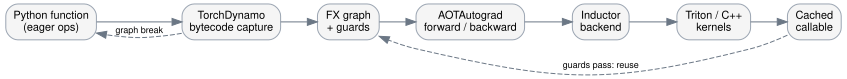

In [2]:
# Draw the stages torch.compile applies to a function.
# Needs the graphviz Python package and the Graphviz "dot" binary. Both are
# preinstalled on Google Colab. Locally: pip install graphviz, and install dot.
from IPython.display import display

try:
    import graphviz
    g = graphviz.Digraph("torch_compile_pipeline")
    g.attr(rankdir="LR", bgcolor="white")
    g.attr("node", shape="box", style="rounded,filled", fillcolor="#f5f5f5",
           color="#9aa4b1", fontname="Helvetica", fontsize="11")
    g.attr("edge", color="#6b7785", fontname="Helvetica", fontsize="9")

    g.node("py",    "Python function\n(eager ops)")
    g.node("dyn",   "TorchDynamo\nbytecode capture")
    g.node("fx",    "FX graph\n+ guards")
    g.node("aot",   "AOTAutograd\nforward / backward")
    g.node("ind",   "Inductor\nbackend")
    g.node("ker",   "Triton / C++\nkernels")
    g.node("cache", "Cached\ncallable")

    for a, b in [("py","dyn"),("dyn","fx"),("fx","aot"),
                 ("aot","ind"),("ind","ker"),("ker","cache")]:
        g.edge(a, b)
    g.edge("dyn", "py", label="graph break", style="dashed", constraint="false")
    g.edge("cache", "fx", label="guards pass: reuse", style="dashed", constraint="false")

    display(g)
except Exception as e:
    print("graphviz not available:", type(e).__name__, e)
    print("Install with:  pip install graphviz   plus the system 'dot' binary.")
    print("On Google Colab both are already present.")

## 1. The two execution models

The notebook reuses a single function throughout:

$$
y = \mathrm{GELU}(xW + b)
$$

In eager mode, PyTorch runs each operation as the Python interpreter reaches it. With `torch.compile`, PyTorch captures a larger region of the function and optimizes it before the function runs repeatedly.

In [3]:
def workload(x, w, b):
    y = x @ w
    y = y + b
    y = F.gelu(y)
    return y

# Moderate size: large enough to be meaningful, small enough for a live demo.
B, D = 1024, 1024

x = torch.randn(B, D, device=device)
w = torch.randn(D, D, device=device)
b = torch.randn(D, device=device)

with torch.no_grad():
    y = workload(x, w, b)

print("Output shape:", y.shape)

Output shape: torch.Size([1024, 1024])


### Before you run the next cell

Count the PyTorch operations in the Python function. At the Python level there are three: a matrix multiplication, an addition, and a GELU.

The relevant compiler question is whether those must remain three separate execution units. For a workload dominated by a matrix multiplication, the matrix multiplication usually stays a specialized GEMM call, while the pointwise work around it can be fused or reorganized.

## 2. Correct benchmarking

GPU execution is asynchronous with respect to the CPU. A naive `time.time()` around a CUDA call can measure host submission rather than completed device work. The cell below therefore synchronizes before and after timing, and reports the median of several runs rather than a single measurement. The timing discipline here, warm up, synchronize, then take a median, is the same one Lecture 3 applied inside its profiling harness; this section states it directly because the compile comparisons that follow depend on it.

In [4]:
def synchronize():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def benchmark(fn, *args, warmup=10, repeats=30, inner=10):
    """Median time per call in ms. Each sample times `inner` calls between two syncs."""
    with torch.no_grad():
        for _ in range(warmup):
            fn(*args)
    synchronize()

    times_ms = []
    with torch.no_grad():
        for _ in range(repeats):
            synchronize()
            t0 = time.perf_counter()
            for _ in range(inner):
                fn(*args)
            synchronize()
            times_ms.append((time.perf_counter() - t0) * 1000 / inner)

    return {
        "median_ms": round(statistics.median(times_ms), 4),
        "min_ms": round(min(times_ms), 4),
        "max_ms": round(max(times_ms), 4),
    }

eager_stats = benchmark(workload, x, w, b)
eager_stats

{'median_ms': 0.1549, 'min_ms': 0.1543, 'max_ms': 0.1575}

## 3. First call versus later calls

The first compiled call is not the steady-state cost. The sequence is:

1. TorchDynamo captures a graph region.
2. Guards are created for the assumptions that make the captured graph valid.
3. The backend compiles the graph.
4. The compiled result is cached.
5. Later calls check the guards and reuse the cached result when it is valid.

The cell measures the cold first call and the steady-state compiled execution.

Inductor caches compiled code on disk, so re-running this section on the same runtime gives a warm start. To force a true cold start, restart the runtime, or set `torch._inductor.config.fx_graph_cache = False` before compiling.

In [5]:
if hasattr(torch, "compile"):
    compiled_workload = torch.compile(workload)

    synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        y_compiled = compiled_workload(x, w, b)
    synchronize()
    first_call_ms = (time.perf_counter() - t0) * 1000

    compiled_stats = benchmark(compiled_workload, x, w, b)

    torch.testing.assert_close(y_compiled, workload(x, w, b), rtol=1e-3, atol=1e-3)

    print(f"Cold first compiled call: {first_call_ms:.3f} ms")
    print("Eager median:", eager_stats["median_ms"], "ms")
    print("Compiled steady-state median:", compiled_stats["median_ms"], "ms")
    print("Steady-state speedup:",
          eager_stats["median_ms"] / compiled_stats["median_ms"])
else:
    print("torch.compile is unavailable in this PyTorch version.")

/usr/local/lib/python3.13/dist-packages/torch/_inductor/compile_fx.py:322: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
  warnings.warn(


Cold first compiled call: 4433.020 ms
Eager median: 0.1549 ms
Compiled steady-state median: 0.1867 ms
Steady-state speedup: 0.8296732726298875


### Cost model

The speedup number on its own does not decide whether to compile. If the function runs only once, compilation can be slower overall. If it runs many times, the compile cost is amortized. The total cost of the compiled path is

$$
T_\text{compiled total} = T_\text{compile} + N \cdot T_\text{compiled steady}
$$

compared with the eager path

$$
T_\text{eager total} = N \cdot T_\text{eager}
$$

where $N$ is the number of calls. Section 10 solves for the value of $N$ at which the two totals are equal.

## 4. The graph TorchDynamo captures

Passing a custom backend to `torch.compile` lets you inspect the captured graph. The backend receives an FX `GraphModule`, which the cell below prints before returning a callable. This exposes the graph-capture stage without needing the full Inductor stack.

In [6]:
captured_graphs = []

def teaching_backend(gm: torch.fx.GraphModule, example_inputs):
    print("\n" + "=" * 80)
    print("CAPTURED FX GRAPH")
    print("=" * 80)
    print(gm.code)
    captured_graphs.append(gm)
    return gm.forward

if hasattr(torch, "compile"):
    graph_only = torch.compile(workload, backend=teaching_backend)

    with torch.no_grad():
        _ = graph_only(x, w, b)

    print("\nNumber of captured graph regions:", len(captured_graphs))


CAPTURED FX GRAPH



def forward(self, L_x_ : torch.Tensor, L_w_ : torch.Tensor, L_b_ : torch.Tensor):
    l_x_ = L_x_
    l_w_ = L_w_
    l_b_ = L_b_
    y = l_x_ @ l_w_;  l_x_ = l_w_ = None
    y_1 = y + l_b_;  y = l_b_ = None
    y_2 = torch._C._nn.gelu(y_1);  y_1 = None
    return (y_2,)
    

Number of captured graph regions: 1


### Visualize the captured graph

The FX `GraphModule` printed above can be drawn as a dataflow graph: each node is an operation, and each edge is a tensor passed from one operation to the next. `FxGraphDrawer` renders it with Graphviz. If Graphviz is not installed, the cell prints the same graph as a table.

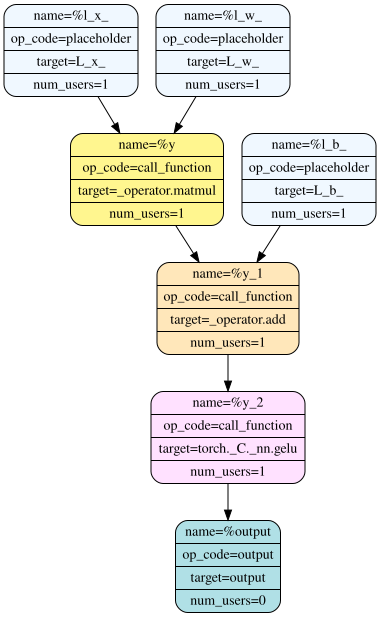

In [7]:
# Draw an FX graph of the real captured/traced object.
# Order: official FxGraphDrawer (needs pydot), then the graphviz package built
# from the actual nodes, then plain text. On Colab the graphviz "dot" binary is
# preinstalled; for the drawer also run:  pip install pydot
from IPython.display import display

def show_fx(module, name="graph"):
    g = module.graph if hasattr(module, "graph") else module
    # 1) official drawer, guarded against an empty SVG from pydot/dot
    try:
        from torch.fx.passes.graph_drawer import FxGraphDrawer
        from IPython.display import SVG
        svg = FxGraphDrawer(module, name).get_dot_graph().create_svg()
        if svg and len(svg) > 120:
            display(SVG(svg)); return
    except Exception:
        pass
    # 2) build the same graph with the graphviz package (no pydot dependency)
    try:
        import graphviz
        dot = graphviz.Digraph(name)
        dot.attr("node", shape="box", fontname="Helvetica", fontsize="10")
        for n in g.nodes:
            if n.op in ("call_function", "call_method", "call_module"):
                label = f"{n.name}\n{n.target}"
            else:
                label = f"{n.op}: {n.name}"
            dot.node(n.name, label)
        for n in g.nodes:
            for inp in n.all_input_nodes:
                dot.edge(inp.name, n.name)
        display(dot); return
    except Exception as e:
        print("Graphviz unavailable (", type(e).__name__, "). Showing the graph as text.\n")
    # 3) text fallback, dependency-free
    try:
        g.print_tabular()
    except Exception:
        print(g)

if captured_graphs:
    show_fx(captured_graphs[0], "workload")
else:
    print("Run the capture cell above first.")

### How to read the graph

Each box is one node in the FX graph. The four lines in a box are the node's fields:

- `name`: the node's name inside the graph, written with a leading `%` (for example `%y`). Later nodes refer to a value by this name.
- `op_code`: the kind of node (the six kinds are listed below).
- `target`: what the node actually refers to or calls. For a `placeholder` it is the input the node stands for. For a `call_function` it is the function: `_operator.matmul` for `x @ w`, `_operator.add` for `y + b`, and `torch._C._nn.gelu` for `F.gelu`.
- `num_users`: how many later nodes read this node's result.

**The six node types (`op_code`).** Every FX node is one of these:

- `placeholder`: a graph input, one per argument of the traced function. The three at the top of this graph are the inputs of `workload(x, w, b)`.
- `call_function`: a call to a free function on tensors, such as `operator.matmul`, `operator.add`, or a `torch` function. The matmul, add, and gelu nodes here are all this type.
- `output`: the value the graph returns. There is exactly one, at the bottom.
- `get_attr`: a read of a parameter or buffer stored on the module, such as a weight tensor. It does not appear here because `workload` takes its weight and bias as arguments rather than holding them as attributes.
- `call_method`: a call to a method on a tensor, such as `x.view(...)` or `x.t()`. None appear in this graph.
- `call_module`: a call to a submodule's `forward`, such as an `nn.Linear` layer. None appear here, but they do in the `nn.Module` example below, where each layer becomes one `call_module` node.

**Input names.** TorchDynamo names each graph input after the Python local variable it came from and wraps it, so `x` becomes `L_x_`, `w` becomes `L_w_`, and `b` becomes `L_b_`. The `L` marks a captured local variable.

Read top to bottom, the graph is the body of `workload`: `%y` is `L_x_ @ L_w_` (the matmul), `%y_1` is `%y + L_b_` (adding the bias), `%y_2` is `gelu(%y_1)`, and `%output` returns `%y_2`. The box colors only group node types and carry no other meaning.

### The same technique on an nn.Module

The capture above used a plain function. Real models are `nn.Module` objects. `torch.fx.symbolic_trace` records a module's forward pass as an FX graph, and `FxGraphDrawer` renders it the same way. `torch.compile` accepts a module directly; the trace here is only to draw the graph. `torchview.draw_graph` is an alternative that also labels tensor shapes.

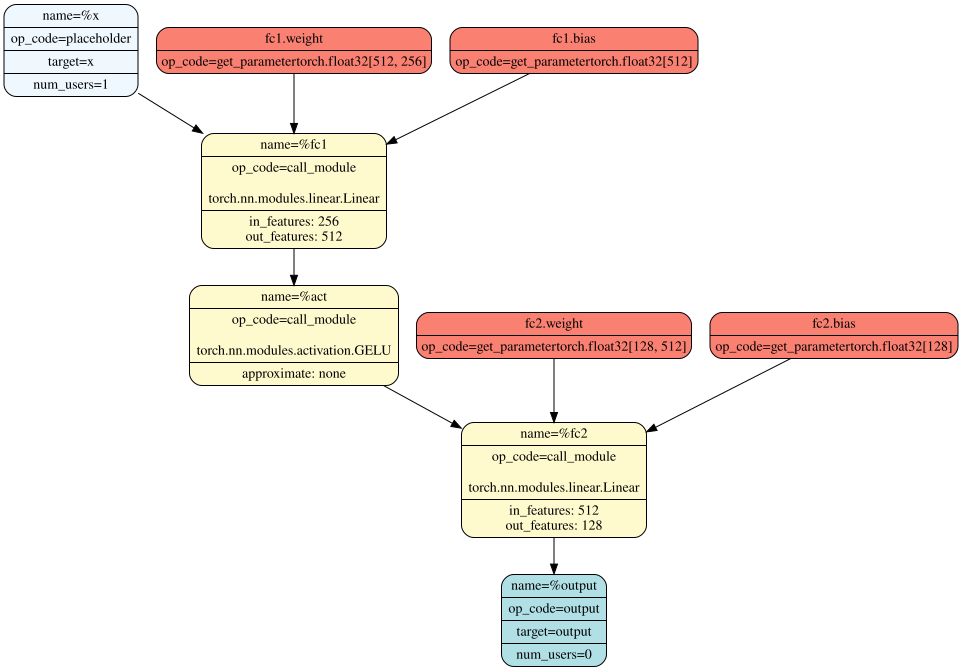

In [8]:
# Draw an FX graph of the real captured/traced object.
# Order: official FxGraphDrawer (needs pydot), then the graphviz package built
# from the actual nodes, then plain text. On Colab the graphviz "dot" binary is
# preinstalled; for the drawer also run:  pip install pydot
from IPython.display import display

def show_fx(module, name="graph"):
    g = module.graph if hasattr(module, "graph") else module
    # 1) official drawer, guarded against an empty SVG from pydot/dot
    try:
        from torch.fx.passes.graph_drawer import FxGraphDrawer
        from IPython.display import SVG
        svg = FxGraphDrawer(module, name).get_dot_graph().create_svg()
        if svg and len(svg) > 120:
            display(SVG(svg)); return
    except Exception:
        pass
    # 2) build the same graph with the graphviz package (no pydot dependency)
    try:
        import graphviz
        dot = graphviz.Digraph(name)
        dot.attr("node", shape="box", fontname="Helvetica", fontsize="10")
        for n in g.nodes:
            if n.op in ("call_function", "call_method", "call_module"):
                label = f"{n.name}\n{n.target}"
            else:
                label = f"{n.op}: {n.name}"
            dot.node(n.name, label)
        for n in g.nodes:
            for inp in n.all_input_nodes:
                dot.edge(inp.name, n.name)
        display(dot); return
    except Exception as e:
        print("Graphviz unavailable (", type(e).__name__, "). Showing the graph as text.\n")
    # 3) text fallback, dependency-free
    try:
        g.print_tabular()
    except Exception:
        print(g)

import torch.nn as nn
from torch.fx import symbolic_trace

class MLP(nn.Module):
    def __init__(self, d_in=256, d_hidden=512, d_out=128):
        super().__init__()
        self.fc1 = nn.Linear(d_in, d_hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(d_hidden, d_out)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

mlp = MLP()
show_fx(symbolic_trace(mlp), "mlp")

### How to read this graph

This is the `MLP` module traced with `symbolic_trace`. The box fields are the same as the graph above, but the node types differ. The layers `self.fc1`, `self.act`, and `self.fc2` are submodules, so each is a `call_module` node whose `target` is the attribute name of the layer. The single `placeholder` is the input `x`, and the `output` node returns the result of `fc2`. Reading top to bottom follows `forward`: `x` enters `fc1`, its result enters `act` (GELU), that enters `fc2`, and `fc2` feeds the output. A `call_module` node keeps the layer whole: the matmul and bias add inside `nn.Linear` are not shown here, because `symbolic_trace` treats a standard module as a single leaf. `torch.compile` traces through those layers to the same operator level as the function graph above.

### What the graph gives you

The captured graph is an intermediate representation. The compiler is no longer reasoning about Python source text; it has a structured representation of tensor operations, and that structure is what makes optimization possible. Note what information is lost and what is gained when the Python code becomes an FX graph.

### 4b. What Inductor generated

`run_and_get_code` returns the code Inductor produced. On a GPU, expect one library call for the matrix multiplication and one fused Triton kernel for the addition and GELU.

In [9]:
import re
from torch._inductor.utils import run_and_get_code

torch._dynamo.reset()
with torch.no_grad():
    _, codes = run_and_get_code(torch.compile(workload), x, w, b)

print("Library calls and generated kernels:")
for line in codes[0].splitlines():
    if re.search(r"extern_kernels\.\w+\(|triton_\w+\.run\(|cpp_fused_\w+\(", line):
        print("  ", line.strip()[:120])

Library calls and generated kernels:
   extern_kernels.mm(arg0_1, arg1_1, out=buf0)
   triton_poi_fused_add_gelu_0.run(buf1, arg2_1, 1048576, stream=stream0)


### How to read the generated code

The filter prints only the lines that launch a kernel. Two lines appear:

- `extern_kernels.mm(arg0_1, arg1_1, out=buf0)`: the matrix multiply stays a call to an external library kernel (cuBLAS). Inductor does not generate its own GEMM; it reuses the tuned library routine.
- `triton_poi_fused_add_gelu_0.run(...)`: the bias add and the GELU are compiled into one generated Triton kernel that reads the matmul result and the bias. The name encodes this: `triton` for the backend, `poi` for pointwise, and `fused_add_gelu` for the two operations combined into one kernel.

So the three Python operations become one library call plus one fused kernel. The matmul runs on its own, and the elementwise add and GELU run together in a single pass over the data. That fusion removes an extra kernel launch and an extra read and write of the intermediate tensor.

## 5. Guards and recompilation

A compiled variant is correct only under the assumptions captured as guards. Changing any of:
- shape,
- dtype,
- device,
- Python values used for specialization,
- module state,

can invalidate the guards and cause PyTorch to create another compiled variant. The cell enables recompilation logging and calls the same function with changing shapes.

Logging syntax changes slightly across PyTorch versions. `TORCH_LOGS="recompiles"` is the setting used here.

In [10]:
from torch._dynamo.testing import CompileCounterWithBackend

torch._dynamo.reset()
# TORCH_LOGS set through os.environ after import has no effect. Use the logging API.
torch._logging.set_logs(recompiles=True)

def shape_sensitive(x):
    return torch.sin(x) + torch.cos(x)

cnt = CompileCounterWithBackend("inductor")
compiled_shape_sensitive = torch.compile(shape_sensitive, backend=cnt)

for n in [8, 16, 32, 64]:
    t = torch.randn(n, 256, device=device)
    with torch.no_grad():
        out = compiled_shape_sensitive(t)
    print("ran batch", n, "-> compiles so far:", cnt.frame_count)

torch._logging.set_logs()  # turn logging back off
print("Total compiles:", cnt.frame_count, "(compare with Check 04)")

V1005 15:54:29.282000 2113 torch/_dynamo/guards.py:4760] [0/1] [__recompiles] Recompiling function shape_sensitive in /tmp/ipykernel_2113/109226249.py:7
V1005 15:54:29.282000 2113 torch/_dynamo/guards.py:4760] [0/1] [__recompiles]     triggered by the following guard failure(s):
V1005 15:54:29.282000 2113 torch/_dynamo/guards.py:4760] [0/1] [__recompiles]     - 0/0: tensor 'x' size mismatch at index 0. expected 8, actual 16


ran batch 8 -> compiles so far: 1
ran batch 16 -> compiles so far: 2
ran batch 32 -> compiles so far: 2
ran batch 64 -> compiles so far: 2
Total compiles: 2 (compare with Check 04)


### Interpretation

For simple code, PyTorch may start with a specialized shape and later generalize a changing dimension symbolically. The accurate statement is not "the second size always becomes dynamic." It is: after a shape-triggered recompile, PyTorch may generalize a changing dimension when the program permits symbolic reasoning. That distinction matters for real models.

### 5b. Mark the dimension before the first call

`mark_dynamic` makes the first compile dynamic, so the same shape sweep compiles once instead of several times.

In [11]:
torch._dynamo.reset()
cnt2 = CompileCounterWithBackend("inductor")
f2 = torch.compile(shape_sensitive, backend=cnt2)

t = torch.randn(8, 256, device=device)
torch._dynamo.mark_dynamic(t, 0)
with torch.no_grad():
    f2(t)
    for n in [16, 32, 64]:
        f2(torch.randn(n, 256, device=device))
print("Compiles with mark_dynamic:", cnt2.frame_count)

Compiles with mark_dynamic: 1


## 6. A graph break

Here we deliberately place host-side Python behavior in the middle of the tensor program. A graph break means the compiled region ends, execution returns to Python and eager behavior, and capture resumes afterward.

A graph break is not the same as a guard failure. A guard failure selects or creates another compiled specialization. A graph break creates an eager boundary inside the program.

In [12]:
def with_graph_break(x):
    y = x * 2

    # Python-side behavior that is intentionally difficult/unhelpful
    # to keep inside the tensor graph.
    print("Python print inside the function; numel =", x.numel())

    z = torch.sin(y)
    return z + 1

if hasattr(torch, "_dynamo"):
    torch._dynamo.reset()

if hasattr(torch, "compile"):
    graph_break_demo = torch.compile(with_graph_break)
    demo_x = torch.randn(16, 16, device=device)

    with torch.no_grad():
        _ = graph_break_demo(demo_x)

Python print inside the function; numel = 256


In [13]:
# Count the graphs and read the break reason.
torch._dynamo.reset()
ex = torch._dynamo.explain(with_graph_break)(demo_x)
print("Graphs:", ex.graph_count, "| Breaks:", ex.graph_break_count)
for r in ex.break_reasons:
    print("Reason:", r.reason)

Python print inside the function; numel = 256
Graphs: 2 | Breaks: 1
Reason: Failed to trace builtin operator
  Explanation: Dynamo does not know how to trace builtin operator `print` with argument types ['str', 'int'] (has_kwargs False)
  Hint: Avoid calling builtin `print` with argument types ['str', 'int']. Consider using an equivalent alternative function/method to `print`.
  Hint: If you are attempting to call a logging function (e.g. `print`), you can try adding it to `torch._dynamo.config.reorderable_logging_functions`.
  Hint: Please report an issue to PyTorch.

  Developer debug context: builtin print [<class 'torch._dynamo.variables.constant.ConstantVariable'>, <class 'torch._dynamo.variables.constant.ConstantVariable'>] False

 For more details about this graph break, please visit: https://meta-pytorch.github.io/compile-graph-break-site/gb/gb0059.html


### fullgraph=True

Setting `fullgraph=True` changes the question from "how much of this could PyTorch compile?" to "can PyTorch capture this entire function as one graph?" It is a diagnostic, not a default performance setting.

In [14]:
if hasattr(torch, "compile"):
    try:
        fullgraph_demo = torch.compile(with_graph_break, fullgraph=True)
        with torch.no_grad():
            _ = fullgraph_demo(torch.randn(8, 8, device=device))
    except Exception as e:
        print("As expected, fullgraph=True exposed the capture problem.")
        print("Exception type:", type(e).__name__)
        print(str(e)[:1200])

As expected, fullgraph=True exposed the capture problem.
Exception type: Unsupported
Failed to trace builtin operator
  Explanation: Dynamo does not know how to trace builtin operator `print` with argument types ['str', 'int'] (has_kwargs False)
  Hint: Avoid calling builtin `print` with argument types ['str', 'int']. Consider using an equivalent alternative function/method to `print`.
  Hint: If you are attempting to call a logging function (e.g. `print`), you can try adding it to `torch._dynamo.config.reorderable_logging_functions`.
  Hint: Please report an issue to PyTorch.

  Developer debug context: builtin print [<class 'torch._dynamo.variables.constant.ConstantVariable'>, <class 'torch._dynamo.variables.constant.ConstantVariable'>] False

 For more details about this graph break, please visit: https://meta-pytorch.github.io/compile-graph-break-site/gb/gb0059.html

from user code:
   File "/tmp/ipykernel_2113/93282354.py", line 6, in with_graph_break
    print("Python print insid

## 7. Python control flow versus tensor control flow

A Python `if` whose branch depends on tensor data must move information from the tensor program into host control flow. A tensor expression such as `torch.where` keeps the decision inside the tensor computation.

This does not mean `torch.where` is semantically equivalent to every Python branch. It is an example of tensorized control flow. `torch.cond` is the general form: it keeps both branches in the graph when both are traceable and return tensors with matching shapes and dtypes.

In [15]:
def python_branch(x):
    # Tensor data influences Python control flow.
    if x.sum().item() > 0:
        return x * 2
    else:
        return x - 2

def with_cond(x):
    # Both branches stay in the graph.
    return torch.cond(x.sum() > 0, lambda x: x * 2, lambda x: x - 2, (x,))

def tensorized(x):
    # Entire expression remains in tensor operations.
    return torch.where(x > 0, x * 2, x - 2)

demo = torch.randn(128, device=device)

if hasattr(torch, "compile"):
    for name, fn in [("python_branch", python_branch),
                     ("tensorized", tensorized),
                     ("with_cond", with_cond)]:
        if hasattr(torch, "_dynamo"):
            torch._dynamo.reset()
        print("\n---", name, "---")
        try:
            compiled_fn = torch.compile(fn, fullgraph=True)
            with torch.no_grad():
                _ = compiled_fn(demo)
            print("Captured as a full graph.")
        except Exception as e:
            print("Full-graph capture failed:", type(e).__name__)
            print(str(e)[:700])


--- python_branch ---
Full-graph capture failed: UserError
Consider annotating your code using torch._check*(). Could not guard on data-dependent expression zuf0 > 0.0 (unhinted: zuf0 > 0.0).  (Size-like symbols: none)

consider using data-dependent friendly APIs such as guard_or_false, guard_or_true and statically_known_true.
Caused by: if x.sum().item() > 0:  # mp/ipykernel_2113/3741616178.py:3 in python_branch (_dynamo/variables/tensor.py:1951 in evaluate_expr)
For more information, run with TORCH_LOGS="dynamic"
For extended logs when we create symbols, also add TORCHDYNAMO_EXTENDED_DEBUG_CREATE_SYMBOL="zuf0"
If you suspect the guard was triggered from C++, add TORCHDYNAMO_EXTENDED_DEBUG_CPP=1
For more debugging help, see https://docs.google.com/

--- tensorized ---
Captured as a full graph.

--- with_cond ---
Captured as a full graph.


## 8. Fusion with a pointwise workload

The earlier matrix-multiply example is dominated by a highly optimized GEMM. A compiler cannot speed up a kernel that already dominates runtime and already runs near the hardware limit.

To make fusion visible, use a chain of pointwise operations. In eager execution those operations are typically separate kernel launches on CUDA and may materialize intermediate tensors. A compiler can often fuse several of them into one kernel.

In [16]:
def pointwise_chain(x):
    a = x * 1.1
    b = torch.sin(a)
    c = b + 0.3
    d = torch.tanh(c)
    e = d * d
    return e

# Large pointwise tensor.
N = 8_000_000 if torch.cuda.is_available() else 2_000_000
px = torch.randn(N, device=device)

point_eager = benchmark(pointwise_chain, px, warmup=5, repeats=20)
print("Eager pointwise:", point_eager)

if hasattr(torch, "compile"):
    if hasattr(torch, "_dynamo"):
        torch._dynamo.reset()

    point_compiled_fn = torch.compile(pointwise_chain)

    # Time the first call: it includes compilation.
    synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        _ = point_compiled_fn(px)
    synchronize()
    point_first_call_ms = (time.perf_counter() - t0) * 1000
    print(f"Cold first call (pointwise): {point_first_call_ms:.1f} ms")

    point_compiled = benchmark(point_compiled_fn, px, warmup=5, repeats=20)

    print("Compiled pointwise:", point_compiled)
    print("Steady-state speedup:",
          point_eager["median_ms"] / point_compiled["median_ms"])

Eager pointwise: {'median_ms': 0.2603, 'min_ms': 0.2595, 'max_ms': 0.2616}
Cold first call (pointwise): 629.7 ms
Compiled pointwise: {'median_ms': 0.0683, 'min_ms': 0.0665, 'max_ms': 0.0819}
Steady-state speedup: 3.81112737920937


### Comparing the two workloads

**GEMM-dominated function**
- an expensive matrix multiplication dominates;
- PyTorch already dispatches to an optimized library kernel;
- the compiler has little left to optimize.

**Pointwise chain**
- repeated launches and memory traffic dominate;
- there is more to fuse;
- `torch.compile` can produce a larger optimized region.

The expected speedup from compilation depends on the bottleneck.

## 9. Profiler: eager versus compiled

Lecture 3 covered the profiler in depth: reading `key_averages` tables and opening a trace in Perfetto. Here the profiler answers one new question: does compilation change the number of kernels? The comparison below counts operator and kernel events for the eager and compiled versions, so the fusion from section 8 appears as fewer kernel rows and a smaller device-time total. The table works in any environment; a timeline view comes from opening a trace in TensorBoard or Chrome.

In [17]:
from torch.profiler import profile, ProfilerActivity

# Newer releases name the GPU column device_time_total; older ones use cuda_time_total.
SORT_KEY = "self_cpu_time_total"
if torch.cuda.is_available():
    SORT_KEY = "device_time_total"

activities = [ProfilerActivity.CPU]
if torch.cuda.is_available():
    activities.append(ProfilerActivity.CUDA)

def profile_once(fn, x):
    with profile(
        activities=activities,
        record_shapes=True,
        profile_memory=True,
    ) as prof:
        with torch.no_grad():
            for _ in range(5):
                fn(x)
        synchronize()
    return prof

# Eager
prof_eager = profile_once(pointwise_chain, px)
print("EAGER PROFILE")
print(prof_eager.key_averages().table(
    sort_by=SORT_KEY,
    row_limit=15
))

if hasattr(torch, "compile"):
    # Compile before profiling to avoid mixing compilation with steady-state execution.
    with torch.no_grad():
        _ = point_compiled_fn(px)
    synchronize()

    prof_compiled = profile_once(point_compiled_fn, px)
    print("\nCOMPILED PROFILE")
    print(prof_compiled.key_averages().table(
        sort_by=SORT_KEY,
        row_limit=15
    ))

EAGER PROFILE
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                              aten::mul         6.50%     212.992us        74.77%       2.452ms     245.173us     498.970us        39.60%     549.657us      54.966us           0 B           0 B     305.18 M

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


### How to read the profiler table

You read `key_averages` tables and Perfetto traces in Lecture 3; this is a brief refresher focused on the one comparison that matters here.

Each row is one operator or one device kernel, sorted by GPU time. The columns that matter here:

- `Name`: the operator (`aten::mul`, `aten::sin`) or the device kernel it launched (`void at::native::vectorized_elementwise_kernel<...>`). An operator and the kernel it runs both appear as separate rows.
- `Self CUDA`: time on the GPU inside that row alone, not counting children. This is the number that reflects real device work.
- `Self CPU` and `CPU total`: time on the host spent dispatching and setting up the call. A large `CPU total` with a small `Self CUDA` means the cost is launch overhead, not computation.
- `# of Calls`: how many times the row ran in the profiled window.
- `CUDA Mem` and `Self CUDA Mem`: device memory the row allocated.

Compare the eager and compiled profiles by two things: the number of distinct kernel rows, and the `Self CUDA time total` printed at the bottom. The compiled pointwise chain collapses several elementwise kernels into one, so it has fewer rows and a smaller total device time.

### Questions to answer from the profiler output

1. Are there fewer framework and operator events after compilation?
2. Which workload is compute-dominated?
3. Which workload is dominated by launches and memory traffic?
4. Does a smaller CPU time automatically imply faster GPU execution?
5. Why must compilation be excluded from the steady-state profile?

## 10. Compilation amortization

A compiled model can be faster in steady state and still be the wrong choice for a short-running job. The break-even iteration count is

$$
N_\text{break-even} = \frac{T_\text{compile}}{T_\text{eager} - T_\text{compiled}}
$$

valid when the denominator is positive.

In [18]:
def break_even_report(name, eager_ms, compiled_ms, compile_ms):
    print(f"--- {name} ---")
    print(f"Eager steady-state:    {eager_ms:.3f} ms")
    print(f"Compiled steady-state: {compiled_ms:.3f} ms")
    print(f"First compiled call:   {compile_ms:.1f} ms")
    if eager_ms > compiled_ms:
        print(f"Break-even calls:      {compile_ms / (eager_ms - compiled_ms):,.0f}")
    else:
        print("No steady-state speedup, so compiling never pays off for this workload.")

if hasattr(torch, "compile"):
    break_even_report("GEMM workload", eager_stats["median_ms"], compiled_stats["median_ms"], first_call_ms)
    break_even_report("Pointwise chain", point_eager["median_ms"], point_compiled["median_ms"], point_first_call_ms)

--- GEMM workload ---
Eager steady-state:    0.155 ms
Compiled steady-state: 0.187 ms
First compiled call:   4433.0 ms
No steady-state speedup, so compiling never pays off for this workload.
--- Pointwise chain ---
Eager steady-state:    0.260 ms
Compiled steady-state: 0.068 ms
First compiled call:   629.7 ms
Break-even calls:      3,280


### Visualize the break-even point

Each workload has a call count where the compiled total, including the one-time compile cost, equals the eager total. Below that count eager is cheaper; above it the compiled version is cheaper. The crossover is at a much higher call count for the GEMM than for the pointwise chain.

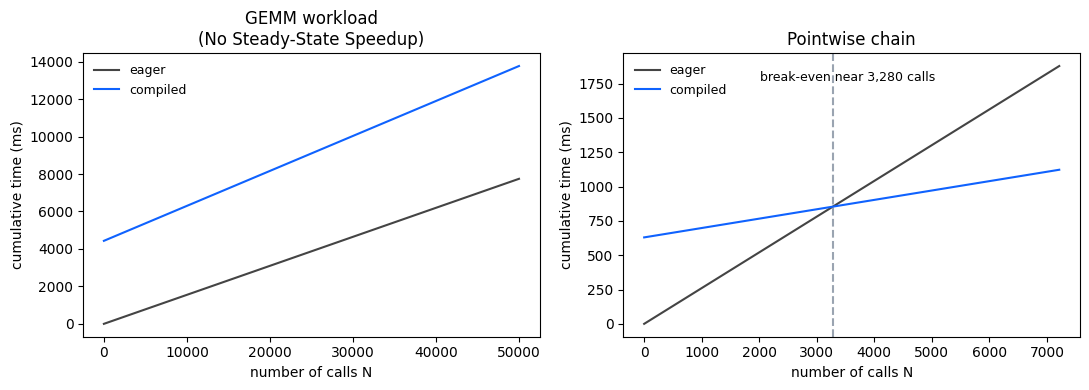

In [19]:
# What this plot shows:
#   For each workload it draws cumulative time (total time after N calls) against
#   the number of calls N. Two lines are compared:
#       eager    : N * eager_ms                 starts at 0, slope = eager per-call time
#       compiled : compile_ms + N * compiled_ms starts at the one-time compile cost,
#                                               slope = compiled per-call time (smaller)
#
# What "crossover" means:
#   The crossover, or break-even, is the call count N where the two lines meet, so the
#   eager total equals the compiled total. Left of it eager has spent less time overall;
#   right of it compiled has, because its lower per-call time has made up for the compile
#   cost. The dashed vertical line marks this N. It is computed as
#       n_be = compile_ms / (eager_ms - compiled_ms)
#   which is only defined when compiled is actually faster per call (eager_ms > compiled_ms).
import numpy as np
import matplotlib.pyplot as plt

def crossover(ax, title, eager_ms, compiled_ms, compile_ms):
    # No per-call speedup: the lines never meet, so there is no crossover to mark.
    # Still draw both lines over a fixed range to show that compiled stays above eager.
    if eager_ms <= compiled_ms:
        n = np.linspace(0, 50000, 200)
        ax.plot(n, n * eager_ms, label="eager", color="#444444")
        ax.plot(n, compile_ms + n * compiled_ms, label="compiled", color="#0F62FE")
        ax.set_title(title + "\n(No Steady-State Speedup)")
        ax.set_xlabel("number of calls N")
        ax.set_ylabel("cumulative time (ms)")
        ax.legend(frameon=False, fontsize=9)
        return
    # Compiled is faster per call: find the crossover and draw the range around it.
    n_be = compile_ms / (eager_ms - compiled_ms)
    n = np.linspace(0, n_be * 2.2, 200)
    ax.plot(n, n * eager_ms, label="eager", color="#444444")
    ax.plot(n, compile_ms + n * compiled_ms, label="compiled", color="#0F62FE")
    ax.axvline(n_be, color="#9aa4b1", linestyle="--")   # the crossover / break-even point
    ax.annotate(f"break-even near {n_be:,.0f} calls",
                xy=(0.30, 0.90), xycoords="axes fraction", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("number of calls N")
    ax.set_ylabel("cumulative time (ms)")
    ax.legend(frameon=False, fontsize=9)

# Left panel: the GEMM workload. Right panel: the pointwise chain.
fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 4))
crossover(axL, "GEMM workload",
          eager_stats["median_ms"], compiled_stats["median_ms"], first_call_ms)
crossover(axR, "Pointwise chain",
          point_eager["median_ms"], point_compiled["median_ms"], point_first_call_ms)
fig.tight_layout()
plt.show()

### How to read this plot

The horizontal axis is the number of calls `N`. The vertical axis is cumulative time, the total after `N` calls. Two lines are drawn:

- `eager` (grey): `N x eager_ms`. It starts at zero and rises with the eager per-call time.
- `compiled` (blue): `compile_ms + N x compiled_ms`. It starts high, at the one-time first-call compile cost, then rises with the smaller compiled per-call time, so its slope is shallower.

The dashed vertical line is the break-even count, where the two totals are equal. To its left the eager line is lower, so eager is cheaper overall. To its right the compiled line is lower, so the compiled version has recovered its compile cost and is cheaper from that point on. The GEMM crosses at a much larger `N` because its per-call saving is tiny, while the pointwise chain crosses much sooner because compilation cuts its per-call time by about four times.

Timing jitters between runs. If a run measures no steady-state speedup for a workload (the eager per-call time is not above the compiled one), that panel is titled `No Steady-State Speedup` and draws the two lines over a fixed range of calls with no crossover: the compiled line starts at the compile cost and stays above eager, so compilation never pays off for that workload.

## 11. Optional CUDA demo: `mode="reduce-overhead"`

For launch-bound GPU workloads, `torch.compile(mode="reduce-overhead")` can reduce Python and launch overhead, and can use CUDA Graph optimizations when the workload is compatible. Two points:

- CUDA Graph replay does not fuse kernels.
- It reduces repeated host submission overhead by replaying a captured sequence.

This section is optional because the behavior depends strongly on the device, the model structure, and the PyTorch version.

In [20]:
if torch.cuda.is_available() and hasattr(torch, "compile"):
    if hasattr(torch, "_dynamo"):
        torch._dynamo.reset()

    def many_small_ops(x):
        for _ in range(12):
            x = torch.sin(x) + 0.01
        return x

    small_x = torch.randn(4096, device="cuda")

    eager_small = benchmark(many_small_ops, small_x, warmup=10, repeats=50)

    default_compiled = torch.compile(many_small_ops, mode="default")
    reduce_compiled = torch.compile(many_small_ops, mode="reduce-overhead")

    # Compile both.
    with torch.no_grad():
        _ = default_compiled(small_x)
        _ = reduce_compiled(small_x)
    synchronize()

    default_small = benchmark(default_compiled, small_x, warmup=10, repeats=50)
    reduce_small = benchmark(reduce_compiled, small_x, warmup=10, repeats=50)

    print("Eager:", eager_small)
    print("Compiled/default:", default_small)
    print("Compiled/reduce-overhead:", reduce_small)
else:
    print("CUDA not available; skip this section.")

Eager: {'median_ms': 0.3605, 'min_ms': 0.3556, 'max_ms': 0.4187}
Compiled/default: {'median_ms': 0.0748, 'min_ms': 0.0723, 'max_ms': 0.0799}
Compiled/reduce-overhead: {'median_ms': 0.1334, 'min_ms': 0.1302, 'max_ms': 0.1648}


## 12. Optional advanced demo: an intentional eager boundary

Not every graph break is worth removing. A small region may be unsupported, highly dynamic, rarely executed, or easier to debug eagerly. An explicit compiler boundary is better than an accidental one. Recent PyTorch versions provide `torch.compiler.disable` for this purpose.

In [21]:
if hasattr(torch, "compiler") and hasattr(torch.compiler, "disable"):
    @torch.compiler.disable
    def intentionally_eager(x):
        # Pretend this is unsupported or debugging-heavy Python code.
        return x.cos()

    def mixed_region(x):
        a = x * 2
        b = intentionally_eager(a)
        c = b + 1
        return c

    if hasattr(torch, "_dynamo"):
        torch._dynamo.reset()

    mixed_compiled = torch.compile(mixed_region)
    with torch.no_grad():
        result = mixed_compiled(torch.randn(128, device=device))
    print("Intentional eager boundary ran successfully:", result.shape)
else:
    print("torch.compiler.disable not available in this version.")

Intentional eager boundary ran successfully: torch.Size([128])


# Summary

The results in this notebook support the following table.

| Observation | Likely implication |
|---|---|
| Many small eager ops | Python, dispatch, and launch overhead may matter |
| Long pointwise chains | Fusion may reduce launches and memory traffic |
| One large GEMM dominates | The compiler may have little to optimize |
| First compiled call is slow | Compilation cost must be amortized |
| Same inputs become fast later | Guards passed and cached compiled code was reused |
| Shape or value change triggers compilation | A guard failed or a new specialization was needed |
| Python behavior interrupts capture | Graph break, an eager boundary |
| Variable sequence lengths cause many variants | Investigate dynamic shapes or bucketing |
| GPU trace has launch gaps | Reduce host overhead; fusion or graph replay may help |

## A performance workflow

1. Profile eager execution first.
2. Identify whether the bottleneck is Python and framework, launch, memory, or compute.
3. Try `torch.compile` with default settings.
4. Verify correctness.
5. Separate cold compile cost from warm steady-state performance.
6. Inspect graph breaks and recompiles.
7. Fix only the hot-path problems that matter.
8. Re-profile.
9. Choose a compile mode only when it addresses the observed bottleneck.
10. Benchmark on the actual model, shapes, precision, and hardware.

Compilation is not the objective. The objective is to remove the bottleneck the profiler identified.

---

## Exercise

Replace the toy workload with one of:
- an MLP block,
- a Transformer feed-forward block,
- a small attention block,

then measure and report:
- eager latency,
- cold compile latency,
- steady-state compiled latency,
- the number of graph breaks,
- recompiles under three input shapes,
- the break-even iteration count.